# Week 11–12: Dimensionality Reduction

This notebook combines **Week 11: Principal Component Analysis (PCA)** and **Week 12: t-SNE** using the Iris dataset.

## Week 11 — Principal Component Analysis (PCA)

In [3]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

In [5]:
iris = load_iris()

X = iris.data
y = iris.target

print("Original shape:", X.shape)
print("Features:", iris.feature_names)

Original shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data:")
print(X_scaled[:5])

Scaled data:
[[-0.90068117  1.01900435 -1.34022653 -1.3154443 ]
 [-1.14301691 -0.13197948 -1.34022653 -1.3154443 ]
 [-1.38535265  0.32841405 -1.39706395 -1.3154443 ]
 [-1.50652052  0.09821729 -1.2833891  -1.3154443 ]
 [-1.02184904  1.24920112 -1.34022653 -1.3154443 ]]


In [9]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original shape:", X.shape)
print("New shape:", X_pca.shape)

Original shape: (150, 4)
New shape: (150, 2)


In [11]:
print("First 5 rows after PCA:")
print(X_pca[:5])

First 5 rows after PCA:
[[-2.26470281  0.4800266 ]
 [-2.08096115 -0.67413356]
 [-2.36422905 -0.34190802]
 [-2.29938422 -0.59739451]
 [-2.38984217  0.64683538]]


In [13]:
print("Explained variance ratio:")
print(pca.explained_variance_ratio_)

print("Total variance retained:")
print(pca.explained_variance_ratio_.sum())

Explained variance ratio:
[0.72962445 0.22850762]
Total variance retained:
0.9581320720000164


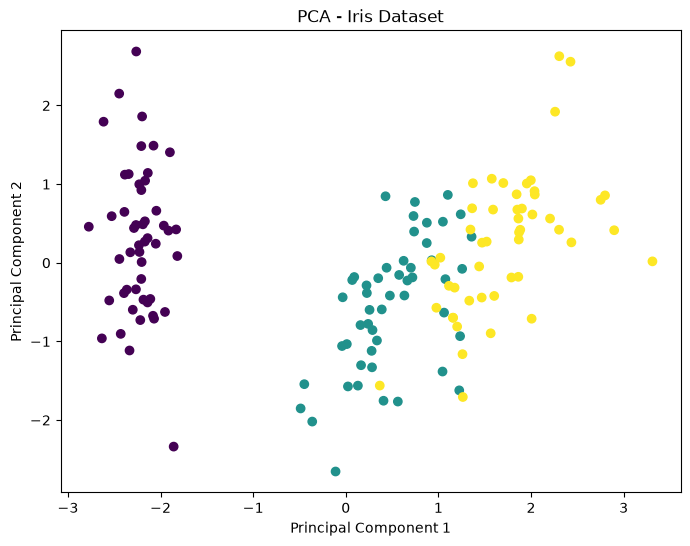

In [15]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=y
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA - Iris Dataset")
plt.show()

In [17]:
print("PCA Components:")

for i, component in enumerate(pca.components_):
    print(f"\nPC{i+1}:")
    
    for feature, value in zip(iris.feature_names, component):
        print(f"{feature}: {value:.4f}")

PCA Components:

PC1:
sepal length (cm): 0.5211
sepal width (cm): -0.2693
petal length (cm): 0.5804
petal width (cm): 0.5649

PC2:
sepal length (cm): 0.3774
sepal width (cm): 0.9233
petal length (cm): 0.0245
petal width (cm): 0.0669


## Week 12 — t-distributed Stochastic Neighbor Embedding (t-SNE)

In [1]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

In [3]:
iris = load_iris()

X = iris.data
y = iris.target

print("Original shape:", X.shape)
print("Features:", iris.feature_names)

Original shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled shape:", X_scaled.shape)

Scaled shape: (150, 4)


In [7]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

X_tsne = tsne.fit_transform(X_scaled)

print("t-SNE shape:", X_tsne.shape)

t-SNE shape: (150, 2)


In [9]:
print("First 5 t-SNE points:")
print(X_tsne[:5])

First 5 t-SNE points:
[[-24.310734   -2.1122737]
 [-20.536928   -1.3836074]
 [-21.545553   -2.4164944]
 [-20.773043   -2.4609888]
 [-24.798649   -2.6877975]]


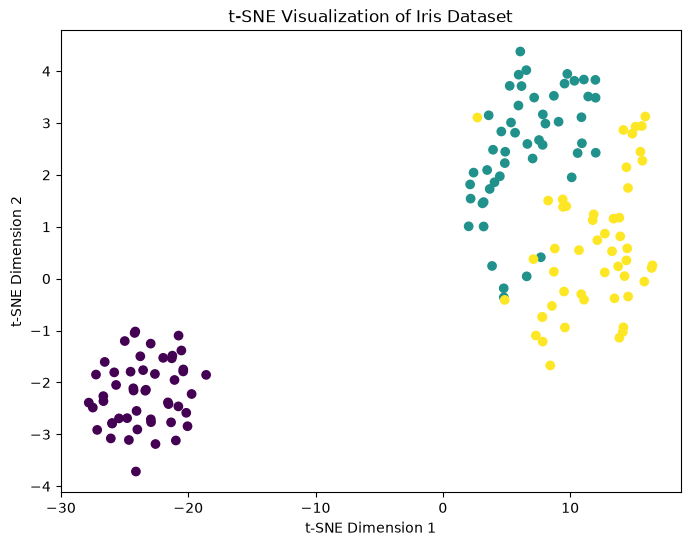

In [11]:
plt.figure(figsize=(8, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=y
)

plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.title("t-SNE Visualization of Iris Dataset")

plt.show()